# Step 05: Model Architecture Customization, Overriding & Modular Ablation

This notebook provides a **modular, multi-representation framework** to edit or override PyTorch model architectures for mmWave radar fall detection.

### Key Features:
- **Multi-Representation Support**: Seamlessly handles **Rep 1** (Doppler-Time Map), **Rep 2** (2D Orthogonal Projections), AND **Rep 3** (3D Point Sets using PointNet++).
- **Modular Architecture Overrides**:
  - **2D Representations (Rep 1 & Rep 2)**: Standard ResNet-18, Narrow ResNet-18 (~700K params), Ultra-Light ResNet-18 (~175K params), and Custom ConvNeXt-style blocks.
  - **3D Point Set Representation (Rep 3)**: Baseline PointNet++ (Conv1D temporal head), PointNet++ with LSTM temporal modeling, PointNet++ with Temporal Attention, and Narrow PointNet++.
- **Multi-Run Benchmarking**: Uses `NUM_RUNS = 3` (seeds 42, 52, 62) to report Mean ± Std for Accuracy, Macro F1, and ROC-AUC.


In [11]:
# Cell 1: System Imports & Setup
%load_ext autoreload
%autoreload 2
import sys
import json
from pathlib import Path
root_dir = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
if str(root_dir) not in sys.path: sys.path.insert(0, str(root_dir))

import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.models import ResNet18Adaptor, PointNetPlusPlusFallDetector, Radar4DCNN, get_model_summary
from src.train_loso import run_loso_cross_validation

sns.set_theme(style="whitegrid")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch Device: {device}")


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
PyTorch Device: cpu


In [12]:
# Cell 2: Select Representation & Multi-Run Hyperparameters
# Pick representation to test: 'rep1' (Doppler-Time), 'rep2' (2D Projections), or 'rep3' (3D Point Sets PointNet++)
REPRESENTATION = "rep3"  # Standard default representation (Change to 'rep1' or 'rep3' anytime!)
NUM_RUNS = 3             # Run 3 distinct random seeds (42, 52, 62) per model variant
EPOCHS = 15
LR = 5e-4
BATCH_SIZE = 32

print(f"Selected Representation: '{REPRESENTATION.upper()}' | NUM_RUNS: {NUM_RUNS} | Epochs: {EPOCHS} | LR: {LR}")


Selected Representation: 'REP3' | NUM_RUNS: 3 | Epochs: 15 | LR: 0.0005


In [ ]:
# Cell 3: Define Custom Architecture Override Factories for 2D (ResNet/ConvNeXt) & 3D (PointNet++)

# --- 2D Representation Overrides (Rep 1 & Rep 2) ---
class NarrowResNet18(nn.Module):
    """Narrow ResNet-18 (Base Channels = 16, ~700K params, Dropout = 0.5)."""
    def __init__(self, in_channels=3, num_classes=2):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(in_channels, 16, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(16), nn.GELU()
        )
        self.layer1 = nn.Sequential(nn.Conv2d(16, 16, 3, padding=1, bias=False), nn.BatchNorm2d(16), nn.GELU())
        self.layer2 = nn.Sequential(nn.Conv2d(16, 32, 3, stride=2, padding=1, bias=False), nn.BatchNorm2d(32), nn.GELU())
        self.layer3 = nn.Sequential(nn.Conv2d(32, 64, 3, stride=2, padding=1, bias=False), nn.BatchNorm2d(64), nn.GELU())
        self.layer4 = nn.Sequential(nn.Conv2d(64, 128, 3, stride=2, padding=1, bias=False), nn.BatchNorm2d(128), nn.GELU())
        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))
        self.fc = nn.Sequential(nn.Dropout(p=0.5), nn.Linear(128, 32), nn.GELU(), nn.Linear(32, num_classes))

    def forward(self, x):
        out = self.stem(x)
        out = self.layer1(out); out = self.layer2(out); out = self.layer3(out); out = self.layer4(out)
        return self.fc(self.avgpool(out).flatten(1))

class UltraLightResNet18(nn.Module):
    """Ultra-Lightweight ResNet-18 (Base Channels = 8, ~175K params, Dropout = 0.5)."""
    def __init__(self, in_channels=3, num_classes=2):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(in_channels, 8, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(8), nn.GELU()
        )
        self.layer1 = nn.Sequential(nn.Conv2d(8, 8, 3, padding=1, bias=False), nn.BatchNorm2d(8), nn.GELU())
        self.layer2 = nn.Sequential(nn.Conv2d(8, 16, 3, stride=2, padding=1, bias=False), nn.BatchNorm2d(16), nn.GELU())
        self.layer3 = nn.Sequential(nn.Conv2d(16, 32, 3, stride=2, padding=1, bias=False), nn.BatchNorm2d(32), nn.GELU())
        self.layer4 = nn.Sequential(nn.Conv2d(32, 64, 3, stride=2, padding=1, bias=False), nn.BatchNorm2d(64), nn.GELU())
        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))
        self.fc = nn.Sequential(nn.Dropout(p=0.5), nn.Linear(64, 16), nn.GELU(), nn.Linear(16, num_classes))

    def forward(self, x):
        out = self.stem(x)
        out = self.layer1(out); out = self.layer2(out); out = self.layer3(out); out = self.layer4(out)
        return self.fc(self.avgpool(out).flatten(1))

# --- 3D Representation Overrides (Rep 3 PointNet++) ---
class PointNetLSTM(nn.Module):
    """PointNet++ with LSTM Temporal Modeling for 3D Point Sets."""
    def __init__(self, in_channels=5, num_classes=2):
        super().__init__()
        self.sa1 = nn.Sequential(nn.Conv1d(in_channels, 64, 1), nn.BatchNorm1d(64), nn.ReLU(), nn.Conv1d(64, 128, 1), nn.BatchNorm1d(128), nn.ReLU())
        self.sa2 = nn.Sequential(nn.Conv1d(128, 256, 1), nn.BatchNorm1d(256), nn.ReLU(), nn.Conv1d(256, 512, 1), nn.BatchNorm1d(512), nn.ReLU())
        self.lstm = nn.LSTM(input_size=512, hidden_size=128, batch_first=True)
        self.fc = nn.Sequential(nn.Dropout(0.4), nn.Linear(128, 64), nn.ReLU(), nn.Linear(64, num_classes))

    def forward(self, x):
        B = x.size(0)
        x_frames = x.view(B * 10, 5, 32)
        f1 = self.sa1(x_frames)
        f2 = self.sa2(f1)
        frame_feat = torch.max(f2, dim=2)[0]  # (B*10, 512)
        temp_seq = frame_feat.view(B, 10, 512)
        _, (h_n, _) = self.lstm(temp_seq)
        return self.fc(h_n[-1])

class PointNetAttention(nn.Module):
    """PointNet++ with Temporal Attention Pooling for 3D Point Sets."""
    def __init__(self, in_channels=5, num_classes=2):
        super().__init__()
        self.sa1 = nn.Sequential(nn.Conv1d(in_channels, 64, 1), nn.BatchNorm1d(64), nn.ReLU(), nn.Conv1d(64, 128, 1), nn.BatchNorm1d(128), nn.ReLU())
        self.sa2 = nn.Sequential(nn.Conv1d(128, 256, 1), nn.BatchNorm1d(256), nn.ReLU(), nn.Conv1d(256, 512, 1), nn.BatchNorm1d(512), nn.ReLU())
        self.attn = nn.Sequential(nn.Linear(512, 128), nn.Tanh(), nn.Linear(128, 1))
        self.fc = nn.Sequential(nn.Dropout(0.4), nn.Linear(512, 64), nn.ReLU(), nn.Linear(64, num_classes))

    def forward(self, x):
        B = x.size(0)
        x_frames = x.view(B * 10, 5, 32)
        f1 = self.sa1(x_frames)
        f2 = self.sa2(f1)
        frame_feat = torch.max(f2, dim=2)[0]  # (B*10, 512)
        temp_seq = frame_feat.view(B, 10, 512)  # (B, 10, 512)
        weights = F.softmax(self.attn(temp_seq), dim=1)
        context = torch.sum(temp_seq * weights, dim=1)
        return self.fc(context)

class NarrowPointNet(nn.Module):
    """Narrow PointNet++ (reduced spatial feature dimensions 64->256, ~250K params)."""
    def __init__(self, in_channels=5, num_classes=2):
        super().__init__()
        self.sa1 = nn.Sequential(nn.Conv1d(in_channels, 32, 1), nn.BatchNorm1d(32), nn.ReLU(), nn.Conv1d(32, 64, 1), nn.BatchNorm1d(64), nn.ReLU())
        self.sa2 = nn.Sequential(nn.Conv1d(64, 128, 1), nn.BatchNorm1d(128), nn.ReLU(), nn.Conv1d(128, 256, 1), nn.BatchNorm1d(256), nn.ReLU())
        self.temporal_conv = nn.Sequential(nn.Conv1d(256, 128, 3, padding=1), nn.BatchNorm1d(128), nn.ReLU(), nn.AdaptiveAvgPool1d(1))
        self.fc = nn.Sequential(nn.Dropout(0.5), nn.Linear(128, 32), nn.ReLU(), nn.Linear(32, num_classes))

    def forward(self, x):
        B = x.size(0)
        x_frames = x.view(B * 10, 5, 32)
        f1 = self.sa1(x_frames)
        f2 = self.sa2(f1)
        frame_feat = torch.max(f2, dim=2)[0]  # (B*10, 256)
        temp_seq = frame_feat.view(B, 10, 256).permute(0, 2, 1)
        temp_feat = self.temporal_conv(temp_seq).squeeze(-1)
        return self.fc(temp_feat)

print("Custom architecture overrides for both 2D (ResNet/ConvNeXt) and 3D (PointNet++) compiled successfully.")


Custom architecture overrides for both 2D (ResNet/ConvNeXt) and 3D (PointNet++) compiled successfully.


In [14]:
# Cell 4: Execute Modular Multi-Run (NUM_RUNS = 3) LOSO Cross-Validation across Architecture Variants
rep_clean = str(REPRESENTATION).lower().strip()

if rep_clean in ('rep1', 'rep2'):
    print(f"Setting up 2D Architecture Experiments for '{rep_clean.upper()}'...")
    experiments = {
        "1. Baseline ResNet-18 (2.81M)": {"fn": lambda: ResNet18Adaptor(in_channels=3, num_classes=2), "wd": 1e-4},
        "2. Narrow ResNet (700K, p=0.5)": {"fn": lambda: NarrowResNet18(in_channels=3, num_classes=2), "wd": 1e-2},
        "3. Ultra-Light ResNet (175K, p=0.5)": {"fn": lambda: UltraLightResNet18(in_channels=3, num_classes=2), "wd": 1e-2},
        "4. Custom ConvNeXt-style (120K, p=0.5)": {"fn": lambda: CustomRadarConvNeXt(in_channels=3, num_classes=2), "wd": 1e-2}
    }
elif rep_clean == "rep3":
    print(f"Setting up 3D Point Set Architecture Experiments for 'REP3' (PointNet++)... ")
    experiments = {
        "1. Baseline PointNet++ (Conv1D, 675K)": {"fn": lambda: PointNetPlusPlusFallDetector(in_channels=5, num_classes=2), "wd": 1e-4},
        "2. PointNet++ with LSTM Temporal Head": {"fn": lambda: PointNetLSTM(in_channels=5, num_classes=2), "wd": 1e-3},
        "3. PointNet++ with Temporal Attention": {"fn": lambda: PointNetAttention(in_channels=5, num_classes=2), "wd": 1e-3},
        "4. Narrow PointNet++ (250K, p=0.5)": {"fn": lambda: NarrowPointNet(in_channels=5, num_classes=2), "wd": 1e-2}
    }
else:
    raise ValueError(f"Unsupported REPRESENTATION '{REPRESENTATION}'. Choose 'rep1', 'rep2', or 'rep3'.")

arch_results = {}
for name, cfg in experiments.items():
    print(f"\n>>> Evaluating Model Variant: '{name}' on '{rep_clean.upper()}' ({NUM_RUNS} Runs) <<<")
    res = run_loso_cross_validation(
        rep_key=rep_clean,
        epochs=EPOCHS,
        lr=LR,
        batch_size=BATCH_SIZE,
        num_runs=NUM_RUNS,
        save_benchmark=False,
        model_fn=cfg["fn"],
        weight_decay=cfg["wd"]
    )
    arch_results[name] = res["test_metrics"]

# Export Master Benchmark JSON
summary_path = Path(f"models/benchmarks/architecture_experiments_summary_{rep_clean}.json")
summary_path.parent.mkdir(parents=True, exist_ok=True)
with open(summary_path, "w", encoding="utf-8") as f:
    json.dump(arch_results, f, indent=4)
print(f"\nExported multi-run architecture benchmark summary to: {summary_path}")


Setting up 3D Point Set Architecture Experiments for 'REP3' (PointNet++)... 

>>> Evaluating Model Variant: '1. Baseline PointNet++ (Conv1D, 675K)' on 'REP3' (3 Runs) <<<

Starting LOSO Cross-Validation for Representation: rep3
Runs: 3 | Seeds: [42, 52, 62] | Epochs: 15 | LR: 0.0005 | Batch Size: 32 | Weight Decay: 0.0001
Custom Model Architecture Function Override Provided!

>>> Starting Run 1/3 (Seed: 42) <<<
Extracting windows from 68 recording files...


Extracting windows from 34 recording files...
  Epoch [05/15] Train Loss: 0.2846, Train Acc: 92.31%
  Epoch [10/15] Train Loss: 0.0685, Train Acc: 99.04%
  Epoch [15/15] Train Loss: 0.0095, Train Acc: 100.00%
Extracting windows from 68 recording files...
Extracting windows from 34 recording files...
  Epoch [05/15] Train Loss: 0.2740, Train Acc: 95.85%
  Epoch [10/15] Train Loss: 0.0308, Train Acc: 99.54%
  Epoch [15/15] Train Loss: 0.0243, Train Acc: 99.54%
Extracting windows from 68 recording files...
Extracting windows from 34 recording files...
  Epoch [05/15] Train Loss: 0.2719, Train Acc: 93.49%
  Epoch [10/15] Train Loss: 0.0406, Train Acc: 100.00%
  Epoch [15/15] Train Loss: 0.0115, Train Acc: 100.00%
Run 1 (Seed 42) Test Result -> Acc: 55.94%, Recall: 23.12%, F1: 50.62%, AUC: 0.6554

>>> Starting Run 2/3 (Seed: 52) <<<
Extracting windows from 68 recording files...
Extracting windows from 34 recording files...
  Epoch [05/15] Train Loss: 0.3014, Train Acc: 94.23%
  Epoch [10/15

=== Model Architecture Benchmark Summary (REP3, 3 Runs Mean ± Std) ===
                        Model Variant   Accuracy (%)      Recall (%)  Precision (%)   Macro F1 (%)         ROC-AUC
1. Baseline PointNet++ (Conv1D, 675K) 60.21% ± 3.87% 40.42% ± 14.03% 66.81% ± 1.33% 57.87% ± 5.91% 0.6789 ± 0.0315
2. PointNet++ with LSTM Temporal Head 50.94% ± 3.06% 24.58% ± 14.58% 49.73% ± 6.68% 46.14% ± 6.07% 0.5174 ± 0.0539
3. PointNet++ with Temporal Attention 59.17% ± 1.03%  41.25% ± 6.90% 65.34% ± 4.49% 57.55% ± 1.10% 0.6055 ± 0.0228
   4. Narrow PointNet++ (250K, p=0.5) 52.60% ± 1.28% 51.46% ± 15.78% 52.54% ± 0.95% 51.50% ± 2.19% 0.5470 ± 0.0179


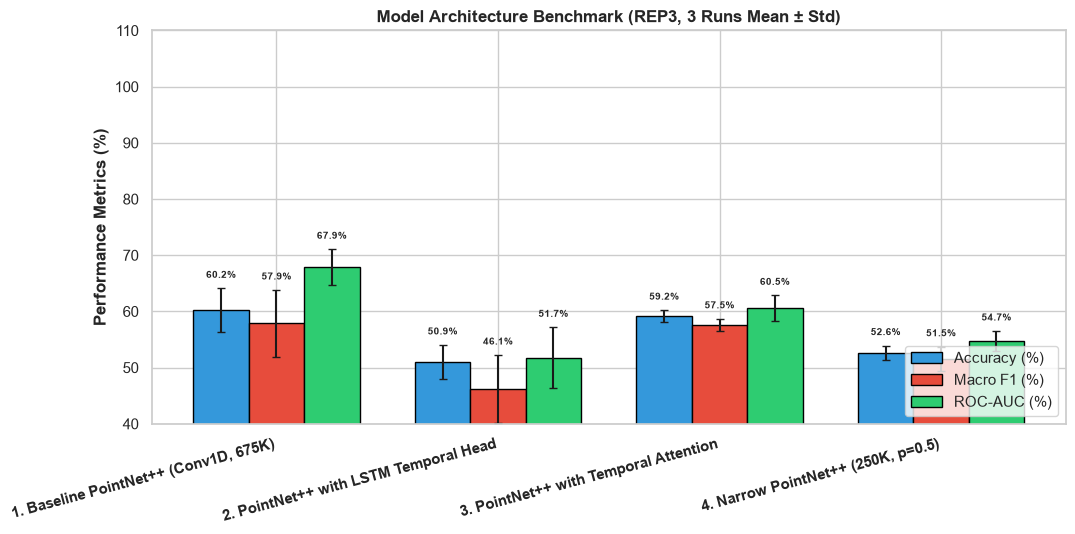

In [15]:
# Cell 5: Compare Results Side-by-Side with Mean ± Std Bars
records = []
for name, m in arch_results.items():
    records.append({
        "Model Variant": name,
        "Accuracy (%)": f"{m['accuracy']*100:.2f}% ± {m['accuracy_std']*100:.2f}%",
        "Recall (%)": f"{m['recall']*100:.2f}% ± {m['recall_std']*100:.2f}%",
        "Precision (%)": f"{m['precision']*100:.2f}% ± {m['precision_std']*100:.2f}%",
        "Macro F1 (%)": f"{m['macro_f1']*100:.2f}% ± {m['macro_f1_std']*100:.2f}%",
        "ROC-AUC": f"{m['roc_auc']:.4f} ± {m['roc_auc_std']:.4f}"
    })

df_comp = pd.DataFrame(records)
print(f"=== Model Architecture Benchmark Summary ({rep_clean.upper()}, {NUM_RUNS} Runs Mean ± Std) ===")
print(df_comp.to_string(index=False))

# Plot Bar Chart with Error Bars (Mean ± Std)
names = list(arch_results.keys())
acc_m = [arch_results[n]["accuracy"] * 100 for n in names]
acc_s = [arch_results[n]["accuracy_std"] * 100 for n in names]
f1_m = [arch_results[n]["macro_f1"] * 100 for n in names]
f1_s = [arch_results[n]["macro_f1_std"] * 100 for n in names]
auc_m = [arch_results[n]["roc_auc"] * 100 for n in names]
auc_s = [arch_results[n]["roc_auc_std"] * 100 for n in names]

fig, ax = plt.subplots(figsize=(11, 5.5), dpi=100)
x = np.arange(len(names))
w = 0.25

b1 = ax.bar(x - w, acc_m, yerr=acc_s, width=w, label="Accuracy (%)", color="#3498db", edgecolor="black", capsize=3)
b2 = ax.bar(x, f1_m, yerr=f1_s, width=w, label="Macro F1 (%)", color="#e74c3c", edgecolor="black", capsize=3)
b3 = ax.bar(x + w, auc_m, yerr=auc_s, width=w, label="ROC-AUC (%)", color="#2ecc71", edgecolor="black", capsize=3)

ax.set_xticks(x)
ax.set_xticklabels(names, rotation=15, ha="right", fontweight="bold")
ax.set_ylabel("Performance Metrics (%)", fontweight="bold")
ax.set_ylim([40, 110])
ax.set_title(f"Model Architecture Benchmark ({rep_clean.upper()}, {NUM_RUNS} Runs Mean ± Std)", fontweight="bold")
ax.legend(loc="lower right")

for bars, stds in zip((b1, b2, b3), (acc_s, f1_s, auc_s)):
    for bar, std in zip(bars, stds):
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., h + std + 1.5, f"{h:.1f}%", ha="center", va="bottom", fontsize=7.5, fontweight="bold")

plt.tight_layout()
plt.show()
